<a href="https://colab.research.google.com/github/RedCombat/SanAntonio-311-Service-Analytics/blob/main/SanAntonio311Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


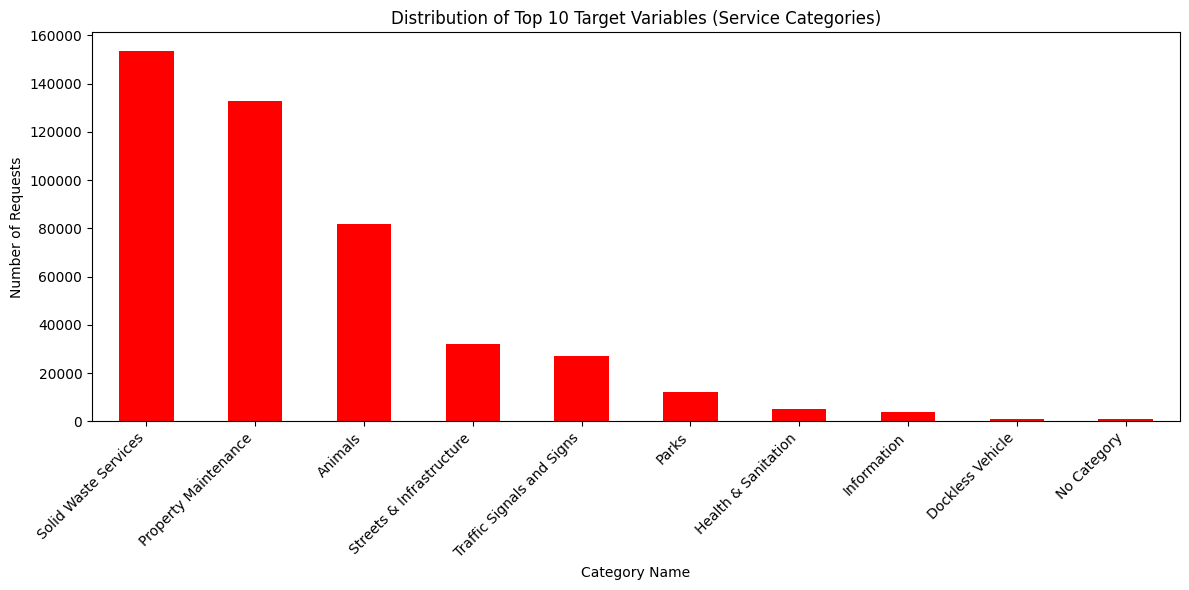

--- Starting Model Training ---
SVM Accuracy: 100.00%
Random Forest Accuracy: 99.96%
Decision Tree Accuracy: 100.00%


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer

#Load the Data
file_path = '/content/drive/MyDrive/311_All_Service_Calls.csv'
df = pd.read_csv(file_path)

# We will visualize the Catergory's which is the target variable
plt.figure(figsize=(12, 6))
target_dist = df['Category'].value_counts().head(10) #Top 10
target_dist.plot(kind='bar', color='red')
plt.title('Distribution of Top 10 Target Variables (Service Categories)')
plt.xlabel('Category Name')
plt.ylabel('Number of Requests')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Create a new column that combines the clues
df['text_input'] = df['Reason Name'].fillna('') + " " + df['Type Name'].fillna('')

# TF-IDF
tfidf = TfidfVectorizer(stop_words='english', max_features=1000)

# 2. Transform the text into a matrix (The Vectors)
X = tfidf.fit_transform(df['text_input'].astype(str))
Y= df['Category']

# 4. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# 5. Modeling (SVM, Random Forest, Decision Tree)
models = {
    "SVM": SVC(kernel='linear'),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=20),
    "Decision Tree": DecisionTreeClassifier(max_depth=20)
}


# Loop to train and evaluate each model
print("--- Starting Model Training ---")
for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    preds = model.predict(X_test)

    # Calculate and print accuracy
    accuracy = accuracy_score(y_test, preds)
    print(f"{name} Accuracy: {accuracy:.2%}")

In [ ]:
# We use coordinates and the text to see if we can predict a delay
# Combine text + coordinates
features = df[['x', 'y', 'Council District']].fillna(0)

# Add the text vectors to the numerical features
import scipy.sparse as sp
X_combined = sp.hstack((X, features))

# Is the case late?
y_late = df['Late (Yes/No)'].map({'YES': 1, 'NO': 0})

# Train/Test Split 80/20
X_train, X_test, y_train, y_test = train_test_split(X_combined, y_late, test_size=0.2)

# Model Evaluation
rf = RandomForestClassifier(n_estimators=100, max_depth=10)
rf.fit(X_train, y_train)
preds = rf.predict(X_test)

print(f"Accuracy for Predicting Lateness: {accuracy_score(y_test, preds):.2%}")

Accuracy for Predicting Lateness: 83.99%


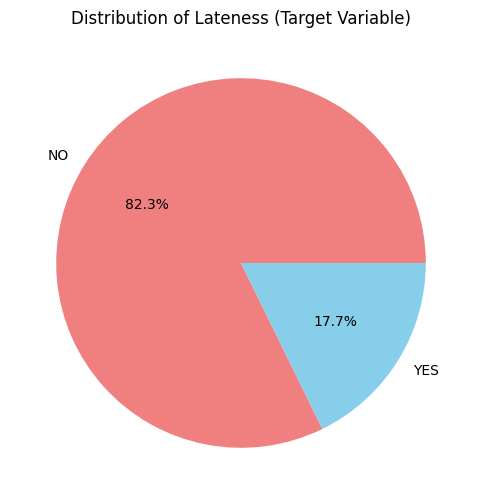

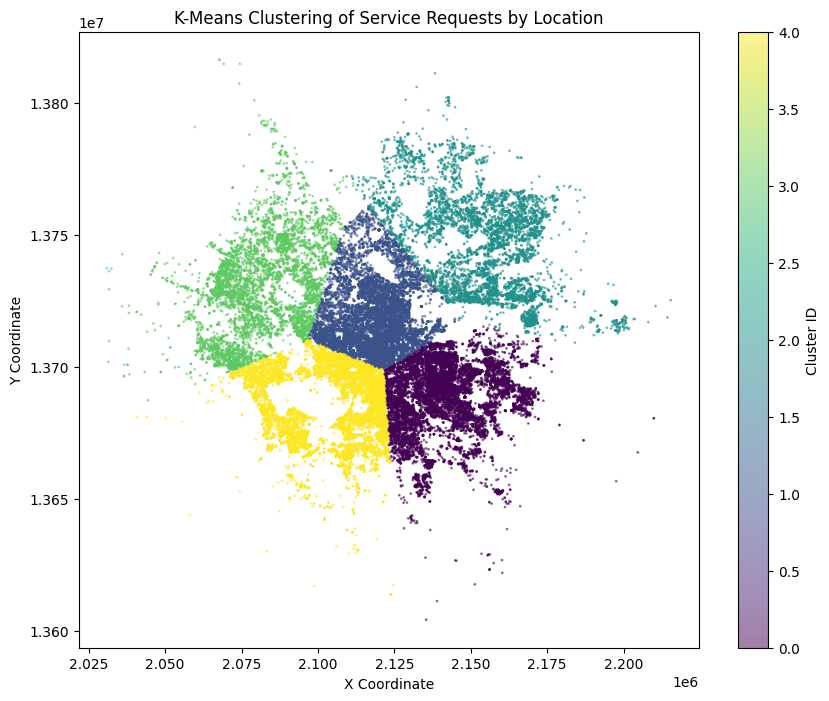

Confusion Matrix:
 [[73546   666]
 [13765  2176]]


In [ ]:
from sklearn.cluster import KMeans
# This proves my 83% accuracy guess
plt.figure(figsize=(6, 6))
df['Late (Yes/No)'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightcoral', 'skyblue'])
plt.title('Distribution of Lateness (Target Variable)')
plt.ylabel('')
plt.show()

# We use the coordinates to find 5 major "Service Zones" in San Antonio
coords = df[['x', 'y']].dropna().head(50000) # Slicing for speed(Google colab doesnt like file with 450k rows)
kmeans = KMeans(n_clusters=5, random_state=42)
df_clusters = coords.copy()
df_clusters['Cluster'] = kmeans.fit_predict(coords)

# Visualize the Clusters
plt.figure(figsize=(10, 8))
plt.scatter(df_clusters['x'], df_clusters['y'], c=df_clusters['Cluster'], cmap='viridis', s=1, alpha=0.5)
plt.title('K-Means Clustering of Service Requests by Location')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.colorbar(label='Cluster ID')
plt.show()

# Instead of just Accuracy, we check how many "NO" cases we missed
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, preds)
print("Confusion Matrix:\n", cm)

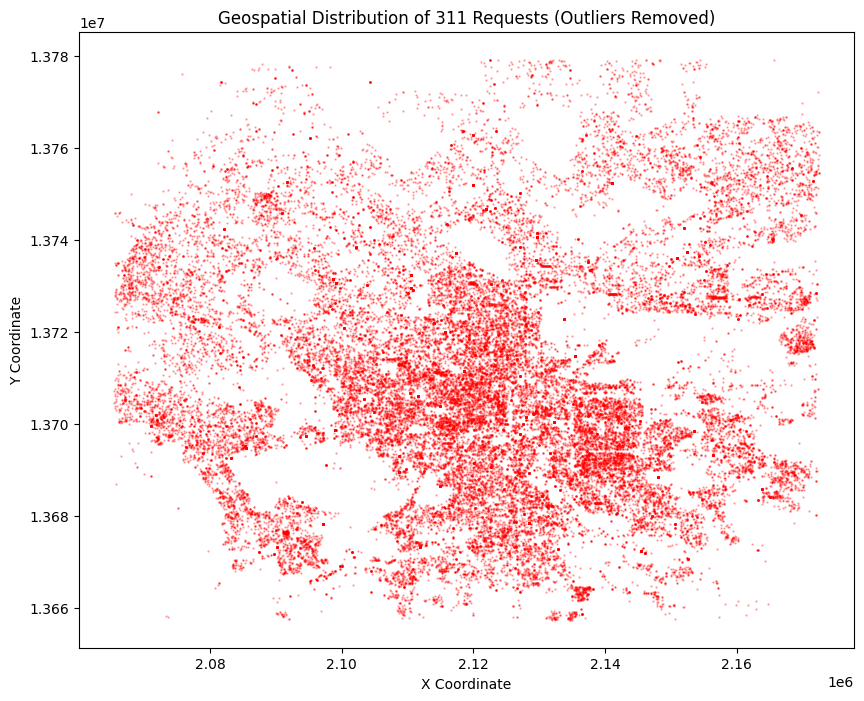

In [ ]:
import numpy as np

# We take the 1st and 99th percentile to cut off the outlier points
x_min, x_max = np.percentile(df['x'].dropna(), [1, 99])
y_min, y_max = np.percentile(df['y'].dropna(), [1, 99])

plt.figure(figsize=(10, 8))
# We only plot data within the City Limits
mask = (df['x'] > x_min) & (df['x'] < x_max) & (df['y'] > y_min) & (df['y'] < y_max)
city_data = df[mask].head(50000) # Slicing for speed

plt.scatter(city_data['x'], city_data['y'], c='red', s=0.5, alpha=0.3)
plt.title('Geospatial Distribution of 311 Requests (Outliers Removed)')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.show()

In [ ]:
# This takes the names of the words from the TF-IDF
feature_names = list(tfidf.get_feature_names_out()) + ['x', 'y', 'Council District']
importances = rf.feature_importances_

# Create a DataFrame to see the top 5 "Predictors"
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
print("Top 5 Features that Predict Lateness:")
print(importance_df.sort_values(by='Importance', ascending=False).head(5))

# Get the probability for each prediction
probs = rf.predict_proba(X_test)
max_probs = probs.max(axis=1)

# We only 'automate' tickets where the model is > % sure
automated_mask95 = max_probs > 0.95
automated_mask90 = max_probs > 0.90
automation_rate95 = automated_mask95.mean()
automation_rate90 = automated_mask90.mean()

print(f"Navy-Style Automation Rate 95% confidence: {automation_rate95:.2%}")
print(f"Navy-Style Automation Rate 90% confidence: {automation_rate90:.2%}")
print("This is the % of tickets the model can route without human help.")

Top 5 Features that Predict Lateness:
        Feature  Importance
103       field    0.100954
57     critical    0.061244
113     garbage    0.042950
9        animal    0.042167
201  operations    0.039261
Navy-Style Automation Rate 95% confidence: 5.09%
Navy-Style Automation Rate 90% confidence: 16.59%
This is the % of tickets the model can route without human help.
